# Детекция ArUco маркеров

Используются классы проекта:

- `PhotoArucoDetector` — обработка одиночного фото
- `VideoArucoDetector` — покадровая обработка видео
- `ArucoDetect` — общий детектор: матрица камеры, `solvePnP`, отрисовка

Запускать из корня проекта (`photo-opu`), ядро — `.venv`. Окна OpenCV не используются, результат выводится через matplotlib.


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.base import DetectionResult
from src.config import settings
from src.detectors import PhotoArucoDetector, VideoArucoDetector


def show_image(image: np.ndarray, title: str = "Результат") -> None:
    plt.figure(figsize=(10, 8))
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


In [ ]:
MARKER_SIZE = 0.2

PHOTO_PATH = settings.input_photo / "test_photo.png"
PHOTO_OUTPUT_PATH = settings.output_photo / "test_result.jpg"

VIDEO_PATH = settings.input_video / "cube_rotation.mov"
VIDEO_OUTPUT_PATH = settings.output_video / "aruco_detection.mp4"


## Фото


Найдено маркеров: 3
ID: [1, 2, 0]
Маркер ID=1: tvec=[0.429 0.191 2.146], центр в координатах камеры=[0.767 1.301 1.595]
Маркер ID=2: tvec=[-0.427  0.224  2.108], центр в координатах камеры=[ 1.367 -1.051  1.306]
Маркер ID=0: tvec=[-0.03  -0.533  2.165], центр в координатах камеры=[-0.718 -1.615  1.36 ]
Маркеры найдены: True


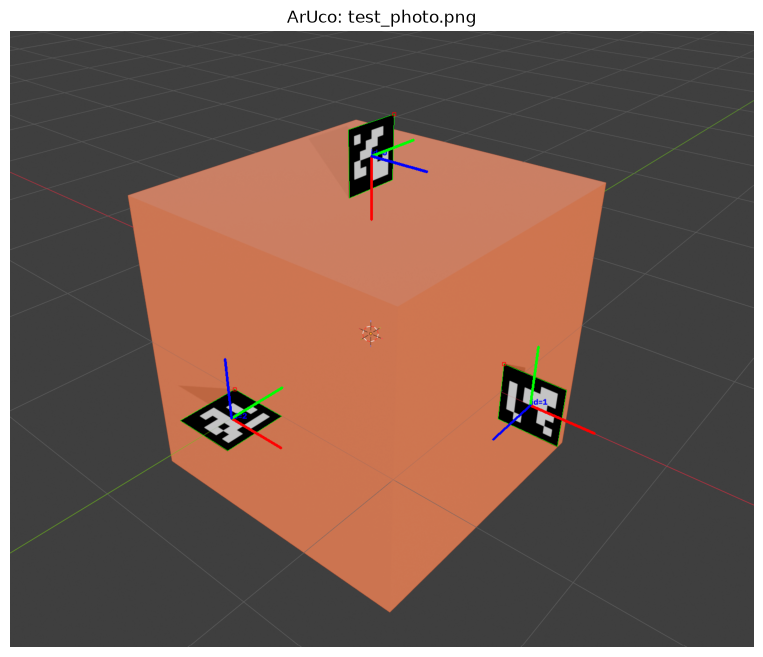

In [ ]:
with PhotoArucoDetector(marker_size=MARKER_SIZE) as detector:
    photo_result = detector.process(
        PHOTO_PATH,
        PHOTO_OUTPUT_PATH,
        show=False,
        save=True,
    )

print(f"Маркеры найдены: {photo_result.found}")
show_image(photo_result.image, f"ArUco: {PHOTO_PATH.name}")


In [8]:
if photo_result.found:
    poses_table = pd.DataFrame(
        [
            {
                "ID": pose.id,
                "tvec, м": np.round(pose.tvec.flatten(), 3).tolist(),
                "центр в системе камеры, м": np.round(pose.center_3d, 3).tolist(),
                "дистанция, м": round(float(np.linalg.norm(pose.center_3d)), 3),
            }
            for pose in photo_result.poses
        ]
    )
else:
    poses_table = pd.DataFrame()

poses_table


,ID,"tvec, м","центр в системе камеры, м","дистанция, м"
0,1,"[0.429, 0.191, 2.146]","[0.767, 1.301, 1.595]",2.197
1,2,"[-0.427, 0.224, 2.108]","[1.367, -1.051, 1.306]",2.163
2,0,"[-0.03, -0.533, 2.165]","[-0.718, -1.615, 1.36]",2.230


## Видео


Кадр 1/250: ID [2]
Кадр 2/250: ID [1, 2]
Кадр 3/250: ID [1, 2]
Кадр 4/250: ID [2]
Кадр 5/250: ID [1, 2]
Кадр 7/250: ID [0]
Кадр 13/250: ID [1, 0]
Кадр 14/250: ID [1, 0]
Кадр 15/250: ID [1]
Кадр 16/250: ID [1, 0]
Кадр 17/250: ID [1]
Кадр 18/250: ID [1, 2]
Кадр 19/250: ID [2]
Кадр 20/250: ID [2]
Кадр 21/250: ID [2]
Кадр 22/250: ID [2]
Кадр 23/250: ID [2]
Кадр 24/250: ID [1, 2]
Кадр 25/250: ID [1, 2]
Кадр 26/250: ID [2, 1]
Кадр 27/250: ID [2, 1]
Кадр 28/250: ID [2, 1]
Кадр 29/250: ID [2, 1]
Кадр 30/250: ID [2, 1]
Кадр 59/250: ID [2, 0]
Кадр 60/250: ID [2, 0]
Кадр 61/250: ID [0, 2]
Кадр 62/250: ID [0, 2]
Кадр 63/250: ID [0, 2]
Кадр 64/250: ID [0, 2]
Кадр 66/250: ID [1]
Кадр 67/250: ID [1]
Кадр 69/250: ID [1]
Кадр 70/250: ID [1]
Кадр 71/250: ID [1]
Кадр 77/250: ID [0]
Кадр 78/250: ID [0]
Кадр 79/250: ID [0]
Кадр 80/250: ID [0]
Кадр 81/250: ID [0]
Кадр 82/250: ID [0]
Кадр 88/250: ID [1]
Кадр 89/250: ID [1]
Кадр 91/250: ID [1]
Кадр 92/250: ID [1]
Кадр 93/250: ID [1]
Кадр 94/250: ID [1]
Кадр 9

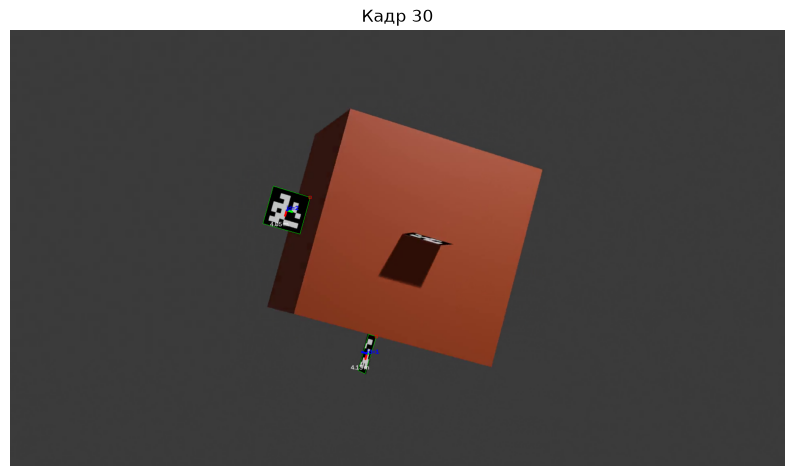

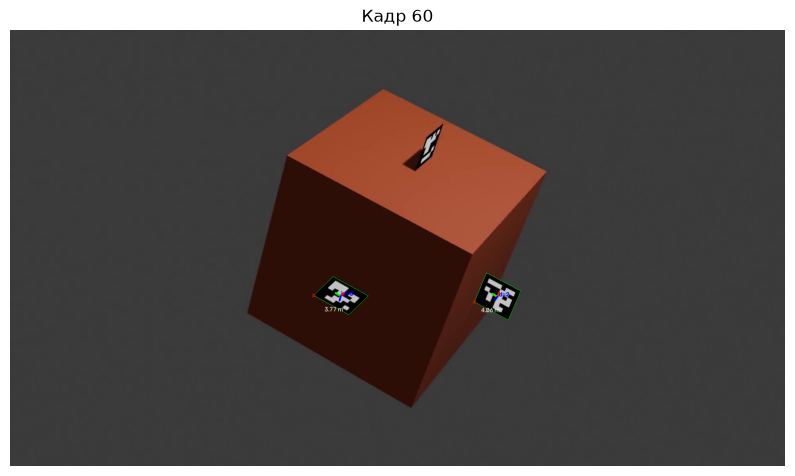

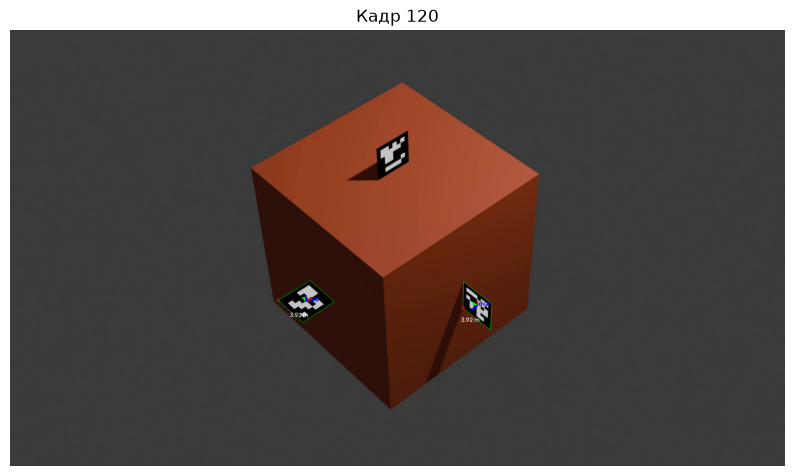

In [9]:
frames_total = 0
frames_with_markers = 0
seen_ids: set[int] = set()
samples: list[DetectionResult] = []

with VideoArucoDetector(marker_size=MARKER_SIZE) as detector:
    for frame_result in detector.process(VIDEO_PATH, VIDEO_OUTPUT_PATH, show=False):
        frames_total += 1
        if frame_result.found and frame_result.ids is not None:
            frames_with_markers += 1
            seen_ids.update(int(marker_id) for marker_id in frame_result.ids)
            frame_index = frame_result.frame_index or 0
            if len(samples) < 3 and frame_index % 30 == 0:
                samples.append(frame_result)

print(f"Кадров обработано: {frames_total}")
print(f"Кадров с маркерами: {frames_with_markers}")
print(f"Встреченные ID: {sorted(seen_ids)}")
print(f"Результат сохранён в: {VIDEO_OUTPUT_PATH}")

for sample in samples:
    show_image(sample.image, f"Кадр {sample.frame_index}")
